# TopGAE on hESC TF knockdown (CRISPRi; Fig. 4A, Fig. S6A, Table S3)

1. **Subset** the Virtual Cell Challenge 2025 H1 hESC CRISPRi data to the 13 perturbed genes that are TFs in the hESC ChIP-seq prior (`RN203.tsv`, SC-MO-GRN-DB) plus 1,000 non-targeting control cells -> `perturb/adata_kd.h5ad`.
2. **DE**: Wilcoxon test of each knockdown vs. non-targeting control (Scanpy) -> `perturb/de_table_kd.csv`.
3. **Training**: TopGAE is trained on control cells with the ChIP-seq prior (TF sources x measured target genes, `split_mode="global"`), five seeds (42-46). Each perturbed TF's outgoing scores are compared with its DE genes, for unseen targets (`unseen_supervision`) and all targets (`all_targets_descriptive`), against the prior alone.

Expected inputs in `perturb/`: `RN203.tsv`, `adata_Training.h5ad`, `adata_Validation.h5ad`, `adata_Test.h5ad`. Results are written to `perturb/perturb_kd_validation/`.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scanpy as sc

In [ ]:
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [2]:
net = pd.read_csv("perturb/RN203.tsv", sep="\t")
net

,Source,Target,Relationship
0,ASH2L,A1BG-AS1,Transcriptional_Regulation
1,ASH2L,A3GALT2,Transcriptional_Regulation
2,ASH2L,AAAS,Transcriptional_Regulation
3,ASH2L,AACS,Transcriptional_Regulation
4,ASH2L,AADACL4,Transcriptional_Regulation
...,...,...,...
822470,ZNF274,ZNF93,Transcriptional_Regulation
822471,ZNF274,ZNF98,Transcriptional_Regulation
822472,ZNF274,ZNF99,Transcriptional_Regulation
822473,ZNF274,ZRANB3,Transcriptional_Regulation


In [5]:
net['Target'].unique().shape

(27386,)

In [3]:
adata_train = sc.read_h5ad("perturb/adata_Training.h5ad")
adata_train

AnnData object with n_obs × n_vars = 221273 × 18080
    obs: 'target_gene', 'guide_id', 'batch'
    var: 'gene_id'

In [4]:
adata_val = sc.read_h5ad("perturb/adata_Validation.h5ad")
adata_val

AnnData object with n_obs × n_vars = 98927 × 18080
    obs: 'target_gene', 'guide_id', 'batch'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mt', 'ribo', 'n_cells'

In [5]:
adata_test = sc.read_h5ad("perturb/adata_Test.h5ad")
adata_test

AnnData object with n_obs × n_vars = 170846 × 18080
    obs: 'target_gene', 'guide_id', 'batch'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mt', 'ribo', 'n_cells'

In [6]:
import anndata as ad
adata = ad.concat([adata_train, adata_val, adata_test])
adata

.../site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 491046 × 18080
    obs: 'target_gene', 'guide_id', 'batch'

In [12]:
adata.obs['target_gene'].unique()

['CHMP3', 'AKT2', 'SHPRH', 'TMSB4X', 'KLF10', ..., 'NELFE', 'INO80B', 'ZFP62', 'NCAPH2', 'ZRSR2']
Length: 301
Categories (301, object): ['AASS', 'ACAT2', 'ACLY', 'ACTN1', ..., 'ZNF714', 'ZNF850', 'ZRSR2', 'non-targeting']

In [7]:
del adata_train, adata_val, adata_test

In [8]:
df_genes = set(net["Source"]).union(set(net["Target"]))
common_genes = df_genes.intersection(set(adata.var.index))
len(common_genes)

17430

In [13]:
pert = adata[adata.obs['target_gene'].isin(net['Source'])]
pert

View of AnnData object with n_obs × n_vars = 16179 × 18080
    obs: 'target_gene', 'guide_id', 'batch'

In [15]:
cont = adata[adata.obs['target_gene'] == 'non-targeting']
n = min(1000, cont.n_obs)
cont = cont[np.random.choice(cont.n_obs, size=n, replace=False)].copy()
cont 

.../site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 1000 × 18080
    obs: 'target_gene', 'guide_id', 'batch'

In [16]:
import anndata as ad
concat = ad.concat([pert, cont])
concat = concat[:, concat.var.index.isin(common_genes)]
concat

.../site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


View of AnnData object with n_obs × n_vars = 17179 × 17430
    obs: 'target_gene', 'guide_id', 'batch'

In [12]:
concat.obs

,target_gene,guide_id,batch
AAACGTTCACTAAGGCACTTTAGG-Flex_1_01,KDM2B,KDM2B_ENST00000377071.4_A|KDM2B_ENST0000037707...,Flex_1_01
AAACTGGGTTTGACTAACTTTAGG-Flex_1_01,TCF3,TCF3_P1P2_A|TCF3_P1P2_B,Flex_1_01
AACCATTTCCATCCTTACTTTAGG-Flex_1_01,TET1,TET1_P1P2_A|TET1_P1P2_B,Flex_1_01
AACCTGCTCCGCCACAACTTTAGG-Flex_1_01,KDM2B,KDM2B_ENST00000377069.4_A|KDM2B_ENST0000037706...,Flex_1_01
AACGTTCGTTCATTGAACTTTAGG-Flex_1_01,RNF2,RNF2_P1P2_A|RNF2_P1P2_B,Flex_1_01
...,...,...,...
TTCTAAGGTTAACGGAACAGACCT-Flex_2_05,non-targeting,non-targeting_00039|non-targeting_01771,Flex_2_05
CAGCTAGAGATTATCCATACGTCA-Flex_3_13,non-targeting,non-targeting_00095|non-targeting_03143,Flex_3_13
ACAATTGAGTTACACTACTACTCA-Flex_2_12,non-targeting,non-targeting_00021|non-targeting_03430,Flex_2_12
CTTATGTAGCGAATACATTCGGTT-Flex_3_16,non-targeting,non-targeting_00065|non-targeting_02434,Flex_3_16


In [13]:
concat.write("perturb/adata_kd.h5ad")

DE Compute

In [14]:
adata = sc.read_h5ad("perturb/adata_kd.h5ad")
adata

.../site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 17179 × 17430
    obs: 'target_gene', 'guide_id', 'batch'

In [15]:
adata.obs['target_gene'].unique()

['KDM2B', 'TCF3', 'TET1', 'RNF2', 'KDM1A', ..., 'RFX5', 'CTBP2', 'CTNNB1', 'ATF4', 'non-targeting']
Length: 14
Categories (14, object): ['ATF4', 'CTBP2', 'CTNNB1', 'EP300', ..., 'TCF3', 'TET1', 'USF2', 'non-targeting']

In [16]:
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

In [18]:
sc.tl.rank_genes_groups(
    adata,
    groupby='target_gene',
    groups=list(set(adata.obs['target_gene']) - {'non-targeting'}),
    reference='non-targeting',
    method='wilcoxon',
)

In [19]:
de_table = sc.get.rank_genes_groups_df(adata, group=None)
de_table

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,CTBP2,TUBB2A,26.167955,0.933556,6.157201e-151,3.577334e-147
1,CTBP2,TUBB2B,24.020248,0.528443,1.708687e-127,5.956483e-124
2,CTBP2,C12orf57,23.377743,0.950222,7.199310e-121,1.568550e-117
3,CTBP2,VCAN,19.260260,0.554174,1.157947e-82,1.681918e-79
4,CTBP2,CRABP2,19.106165,0.970354,2.243644e-81,3.008208e-78
...,...,...,...,...,...,...
226585,USF2,APAF1,-30.374228,-3.218723,1.203032e-202,4.193769e-199
226586,USF2,USF2,-32.661110,-1.603258,5.573323e-234,2.428575e-230
226587,USF2,TELO2,-35.896782,-3.830714,3.429133e-282,1.992326e-278
226588,USF2,ICA1,-37.818459,-4.237243,0.000000e+00,0.000000e+00


In [20]:
de_table.to_csv("perturb/de_table_kd.csv", index=False)

Training

In [21]:
from pathlib import Path
import gc
import json
import time

import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse
from scipy.stats import hypergeom
import torch
from sklearn.metrics import average_precision_score, roc_auc_score

from topgae import (build_adjacency, prepare_inputs, make_splits,
                           validate_splits, seed_everything,
                           TopGAE, train_topgae)



In [22]:
GROUPS = list(set(adata.obs['target_gene']) - {'non-targeting'})
SEEDS = [42, 43, 44, 45, 46]
# Five model initializations, each evaluated for every perturbation group.
# All groups share control expression and RN203, so 30 separate fits are unnecessary.
GROUP_SEEDS = {group: list(SEEDS) for group in GROUPS}
SPLIT_SEED = 314159  # fixed across initializations: same evaluation genes per group
CONTROL_LABEL = 'non-targeting'
GROUP_COLUMN = 'target_gene'
GENE_SYMBOL_COLUMN = None  # None uses adata.var_names; otherwise e.g. 'gene_symbol'
INPUT_IS_LOG_NORMALIZED = False  # saved subset is written before normalization in your notebook
NORMALIZE_TARGET_SUM = 1e4
MIN_CONTROL_CELLS = 10
MAX_TARGET_GENES = None  # optional cap by CONTROL variance; never select using DE
FDR_THRESHOLD = 0.05
MIN_ABS_LOG2FC = 0.25
TOP_K = [50, 100, 200]
SCOPES = ['unseen_supervision', 'all_targets_descriptive']
OUTPUT_DIR = Path('perturb/perturb_kd_validation')

HIDDEN_DIM = 64
LATENT_DIM = 32
DROPOUT = 0.2
LAMBDA_EXPR = 0.5
RECONSTRUCTION_LOSS = 'cosine'
MASK_RATIO = 0.2
NUM_EPOCHS = 2000
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 5e-4
PATIENCE = 50
VAL_CHECK_FREQ = 5
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

In [23]:
DATA_DIR = Path("perturb")
RN203 = pd.read_csv(DATA_DIR / "RN203.tsv", sep="\t")
adata_Training_subset = sc.read_h5ad(DATA_DIR / "adata_kd.h5ad")
de_table_train = pd.read_csv(DATA_DIR / "de_table_kd.csv")

print("RN203:", RN203.shape)
print("Expression:", adata_Training_subset.shape)
print("DE table:", de_table_train.shape)
print(adata_Training_subset.obs[GROUP_COLUMN].value_counts())
display(de_table_train.head())


RN203: (822475, 3)
Expression: (17179, 17430)
DE table: (226590, 6)
target_gene
TET1             2428
EP300            2217
KDM2B            2142
RNF2             1844
CTNNB1           1652
TCF3             1343
USF2             1207
non-targeting    1000
RFX5              919
SOX2              806
ATF4              570
CTBP2             538
KDM1A             352
MAX               161
Name: count, dtype: int64


.../site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


,group,names,scores,logfoldchanges,pvals,pvals_adj
0,CTBP2,TUBB2A,26.167955,0.933556,6.157201e-151,3.577334e-147
1,CTBP2,TUBB2B,24.020248,0.528443,1.708687e-127,5.956483e-124
2,CTBP2,C12orf57,23.377743,0.950222,7.199310e-121,1.568550e-117
3,CTBP2,VCAN,19.260260,0.554174,1.157947e-82,1.681918e-79
4,CTBP2,CRABP2,19.106165,0.970355,2.243644e-81,3.008208e-78


In [24]:
def prepare_controls_and_network(network, adata):
    """No perturbed-cell expression or DE statistics enter model preparation."""
    if not {'Source', 'Target'}.issubset(network.columns):
        raise ValueError('RN203 must have Source and Target columns.')
    if GROUP_COLUMN not in adata.obs:
        raise ValueError(f'adata.obs is missing {GROUP_COLUMN!r}.')
    observed = adata.obs[GROUP_COLUMN].astype(str)
    missing = set(GROUPS) - set(observed)
    if missing:
        raise ValueError(f'Perturbation groups absent from adata: {sorted(missing)}')
    ctrl = adata[observed.eq(CONTROL_LABEL)].copy()
    if ctrl.n_obs < 2:
        raise ValueError('At least two non-targeting control cells are required.')
    names = (pd.Index(ctrl.var_names) if GENE_SYMBOL_COLUMN is None
             else pd.Index(ctrl.var[GENE_SYMBOL_COLUMN]))
    if names.isna().any():
        raise ValueError('Missing gene symbols; resolve gene identifiers first.')
    names = names.astype(str).str.strip()
    if not names.is_unique or (names == '').any():
        raise ValueError('Gene symbols must be nonempty and unique; do not silently rename duplicates.')
    ctrl.var_names = names
    ctrl.X = ctrl.X.astype(np.float32)
    values = ctrl.X.data if sparse.issparse(ctrl.X) else np.asarray(ctrl.X)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError('Expected finite, nonnegative counts or log-normalized expression in .X.')
    detected = np.asarray((ctrl.X > 0).sum(axis=0)).ravel()
    if not INPUT_IS_LOG_NORMALIZED:
        if not np.allclose(values, np.rint(values), atol=1e-4, rtol=0):
            raise ValueError('Non-integer .X: confirm preprocessing. Set INPUT_IS_LOG_NORMALIZED=True only for already log-normalized data.')
        # Normalize on the full assay gene set before selecting model genes.
        sc.pp.normalize_total(ctrl, target_sum=NORMALIZE_TARGET_SUM)
        sc.pp.log1p(ctrl)
    net = network[['Source', 'Target']].copy()
    network_audit = {'input_rows': int(len(net))}
    # Nullable strings preserve missing values (astype(str) would turn NaN into 'nan').
    for c in net:
        net[c] = net[c].astype('string').str.strip()
    invalid = net.isna().any(axis=1) | net.eq('').any(axis=1)
    network_audit['missing_or_blank_endpoint_rows'] = int(invalid.sum())
    net = net.loc[~invalid].copy()
    if net.empty:
        raise ValueError('RN203 has no rows with two nonempty endpoints. Check the input file and column mapping.')
    self_pairs = net.Source.eq(net.Target)
    network_audit['self_pair_rows'] = int(self_pairs.sum())
    net = net.loc[~self_pairs].copy()
    duplicates = net.duplicated(['Source', 'Target'])
    network_audit['duplicate_pair_rows'] = int(duplicates.sum())
    net = net.loc[~duplicates].copy()
    measured = net.Source.isin(names) & net.Target.isin(names)
    network_audit['unmeasured_endpoint_rows'] = int((~measured).sum())
    net = net.loc[measured].copy()
    network_audit['retained_measured_pairs'] = int(len(net))
    print('RN203 cleaning:', network_audit)
    if net.empty:
        raise ValueError('No RN203/expression overlap: check symbols versus Ensembl IDs and GENE_SYMBOL_COLUMN.')
    rows = sorted(net.Source.unique())
    if not set(GROUPS).issubset(rows):
        raise ValueError(f'Query regulators missing from measured RN203 sources: {sorted(set(GROUPS)-set(rows))}')
    cols = names[detected >= MIN_CONTROL_CELLS].tolist()
    if MAX_TARGET_GENES is not None:
        if not isinstance(MAX_TARGET_GENES, int) or MAX_TARGET_GENES < 1:
            raise ValueError('MAX_TARGET_GENES must be None or a positive integer.')
        z = ctrl[:, cols].X
        mean = np.asarray(z.mean(axis=0)).ravel()
        second = np.asarray(z.multiply(z).mean(axis=0)).ravel() if sparse.issparse(z) else np.square(z).mean(axis=0)
        variance = np.maximum(0, second - mean ** 2)
        order = np.argsort(-variance, kind='stable')[:MAX_TARGET_GENES]
        cols = [cols[k] for k in order]
    if not cols:
        raise ValueError('No target genes pass the control-expression filter.')
    genes = list(dict.fromkeys(rows + cols))
    x = ctrl[:, genes].X
    x = x.toarray() if sparse.issparse(x) else np.asarray(x)
    expression = pd.DataFrame(x.T, index=genes, columns=range(ctrl.n_obs), dtype=np.float32)
    prior_df, rows, cols = build_adjacency(net.rename(columns={'Source': 'Gene1', 'Target': 'Gene2'}), rows, cols)
    xr, xc, labels = prepare_inputs(expression, prior_df, rows, cols, 'cpu', normalization='cell')
    audit = dict(n_control_cells=ctrl.n_obs, n_source_genes=len(rows), n_target_genes=len(cols),
                 n_prior_positive=int(labels.sum()), network_cleaning=network_audit,
                 control_obs_names=ctrl.obs_names.astype(str).tolist(),
                 perturbation_cell_counts=observed.value_counts().to_dict(),
                 target_filter='control detection then optional control variance; no DE selection')
    return (xr, xc, labels, rows, cols), audit


def clean_de_table(table):
    required = {'group', 'names', 'pvals_adj', 'logfoldchanges'}
    if not required.issubset(table.columns):
        raise ValueError(f'DE table needs columns {sorted(required)} from rank_genes_groups_df.')
    de = table.copy()
    if de[['group', 'names']].isna().any().any():
        raise ValueError('Missing group/gene names in DE table.')
    de['group'] = de['group'].astype(str).str.strip()
    de['names'] = de['names'].astype(str).str.strip()
    de = de[de.group.isin(GROUPS)].copy()
    if de.duplicated(['group', 'names']).any():
        raise ValueError('Duplicate group/gene DE rows; resolve them before evaluation.')
    for c in ['pvals_adj', 'logfoldchanges']:
        de[c] = pd.to_numeric(de[c], errors='raise')
    finite_p = de.pvals_adj[np.isfinite(de.pvals_adj)]
    if not finite_p.between(0, 1).all():
        raise ValueError('Adjusted DE p-values must lie in [0, 1].')
    if not set(GROUPS).issubset(de.group):
        raise ValueError('The DE table does not contain all requested groups.')
    # Do not filter to significant rows. Non-significant TESTED genes define the background.
    de['DE_evaluable'] = np.isfinite(de.pvals_adj) & np.isfinite(de.logfoldchanges)
    de['DE_positive'] = (de.DE_evaluable & de.pvals_adj.lt(FDR_THRESHOLD)
                         & de.logfoldchanges.abs().ge(MIN_ABS_LOG2FC))
    return de


def bh_adjust(pvalues):
    p = np.asarray(pvalues, dtype=float)
    out = np.full(p.shape, np.nan)
    ok = np.flatnonzero(np.isfinite(p))
    order = ok[np.argsort(p[ok], kind='stable')]
    if len(order):
        adjusted = p[order] * len(order) / np.arange(1, len(order) + 1)
        out[order] = np.minimum(1, np.minimum.accumulate(adjusted[::-1])[::-1])
    return out


def evaluate_scores(frame, seed, group, scope):
    """DE response recovery, not accuracy against a direct-binding ground truth."""
    metrics, topk = [], []
    n = len(frame)
    y = frame.DE_positive.to_numpy(dtype=int)
    d = int(y.sum())
    for method, column in [('TopGAE', 'ModelLogit'), ('RN203_prior', 'PriorEdge')]:
        scores = frame[column].to_numpy(dtype=float)
        identity = dict(Seed=seed, Group=group, Scope=scope, Method=method,
                        NGenes=n, NDE=d, DEPrevalence=d/n if n else np.nan)
        valid = n > 0 and 0 < d < n and np.isfinite(scores).all()
        ap = average_precision_score(y, scores) if valid else np.nan
        metrics.append(dict(**identity, Status='ok' if valid else 'undefined_single_class_or_empty',
                            AUROC=roc_auc_score(y, scores) if valid else np.nan,
                            AP=ap, APLift=ap/(d/n) if valid else np.nan))
        ranked = frame.sort_values([column, 'Gene'], ascending=[False, True], kind='stable')
        for requested in TOP_K:
            k = min(requested, n)
            hits = int(ranked.DE_positive.iloc[:k].sum())
            expected = k*d/n if n else np.nan
            cutoff_tie = bool(0 < k < n and ranked[column].iloc[k-1] == ranked[column].iloc[k])
            topk.append(dict(**identity, RequestedK=requested, K=k, DEHits=hits,
                             PrecisionAtK=hits/k if k else np.nan,
                             RecallAtK=hits/d if d else np.nan,
                             FoldEnrichment=hits/expected if expected > 0 else np.nan,
                             HypergeomP=float(hypergeom.sf(hits-1, n, d, k)) if valid and k else np.nan,
                             TieAtCutoff=cutoff_tie))
    return metrics, topk


def run_validation(RN203, adata_Training_subset, de_table_train):
    if set(GROUP_SEEDS) != set(GROUPS) or len(set(GROUPS)) != len(GROUPS):
        raise ValueError('GROUP_SEEDS must assign seeds to each unique requested GROUP.')
    if any(not v or len(v) != len(set(v)) for v in GROUP_SEEDS.values()):
        raise ValueError('Every group needs a nonempty list of unique seeds.')
    if not 0 < FDR_THRESHOLD < 1 or MIN_ABS_LOG2FC < 0:
        raise ValueError('Invalid predeclared DE thresholds.')
    if any(not isinstance(k, int) or k < 1 for k in TOP_K) or len(TOP_K) != len(set(TOP_K)):
        raise ValueError('TOP_K must contain unique positive integers.')
    out = Path(OUTPUT_DIR)
    out.mkdir(parents=True, exist_ok=True)
    if (out / 'settings.json').exists():
        raise FileExistsError('OUTPUT_DIR contains an earlier experiment. Choose a new directory; no automatic overwrite/resume.')
    # Explicit configuration allowlist: RN203 is uppercase too, but is input data.
    # Never scan all notebook globals or stringify data objects to hide this error.
    config_names = (
        'GROUPS SEEDS GROUP_SEEDS SPLIT_SEED CONTROL_LABEL GROUP_COLUMN '
        'GENE_SYMBOL_COLUMN INPUT_IS_LOG_NORMALIZED NORMALIZE_TARGET_SUM '
        'MIN_CONTROL_CELLS MAX_TARGET_GENES FDR_THRESHOLD MIN_ABS_LOG2FC '
        'TOP_K SCOPES OUTPUT_DIR HIDDEN_DIM LATENT_DIM DROPOUT LAMBDA_EXPR '
        'RECONSTRUCTION_LOSS MASK_RATIO NUM_EPOCHS LEARNING_RATE WEIGHT_DECAY '
        'PATIENCE VAL_CHECK_FREQ DEVICE'
    ).split()
    settings = {name: (str(globals()[name]) if isinstance(globals()[name], Path)
                       else globals()[name]) for name in config_names}
    settings_json = json.dumps(settings, indent=2)
    data, audit = prepare_controls_and_network(RN203, adata_Training_subset)
    xr, xc, full_labels, rows, cols = data
    # This application uses RN203 regulator sources × measured targets (rectangular),
    # rather than the benchmark's all-gene-source GAEDGRN negative universe.
    splits = make_splits(full_labels, rows, cols, seed=SPLIT_SEED, split_mode='global',
                         val_fraction=.05, test_fraction=.10)
    validate_splits(splits, full_labels, rows, cols)
    de = clean_de_table(de_table_train)
    # Write the run marker only after input preparation/validation succeeds.
    audit_json = json.dumps(audit, indent=2)
    (out / 'settings.json').write_text(settings_json, encoding='utf-8')
    torch.save(dict(splits=splits, row_genes=rows, col_genes=cols,
                    split_seed=SPLIT_SEED, control_audit=audit), out / 'fixed_RN203_split.pt')
    (out / 'input_audit.json').write_text(audit_json, encoding='utf-8')
    all_metrics, all_topk, runs, coverage = [], [], [], []
    query_indices = {group: rows.index(group) for group in GROUPS}
    # Only membership of training/validation SUPERVISION is used for exclusion.
    # Test labels and DE results are not used for model selection.
    excluded = {}
    for group, index in query_indices.items():
        excluded[group] = set()
        for edges in (splits[0], splits[2]):
            excluded[group].update(edges[1, edges[0] == index].tolist())
    seeds = sorted(set(s for values in GROUP_SEEDS.values() for s in values))
    for seed in seeds:
        selected_groups = [g for g in GROUPS if seed in GROUP_SEEDS[g]]
        start = time.perf_counter()
        model = logits = fit = None
        record = dict(Seed=seed, Groups=';'.join(selected_groups), Status='error', Error='')
        try:
            seed_everything(seed)
            model = TopGAE(xr.shape[1], HIDDEN_DIM, LATENT_DIM,
                dropout=DROPOUT, use_importance=True, reverse_messages=True, use_s1=True, use_s2=True)
            _, _, logits, fit = train_topgae(
                model, xr, xc, full_labels, rows, cols, splits=splits, seed=seed,
                device=torch.device(DEVICE), num_epochs=NUM_EPOCHS, lr=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY, patience=PATIENCE, val_check_freq=VAL_CHECK_FREQ,
                lambda_expr=LAMBDA_EXPR, mask_ratio=MASK_RATIO,
                reconstruction_loss=RECONSTRUCTION_LOSS, edge_dropout=0.,
                selection_metric='auprc', verbose=True)
            torch.save(dict(state_dict={k:v.detach().cpu() for k,v in model.state_dict().items()},
                            seed=seed, row_genes=rows, col_genes=cols,
                            input_dim=xr.shape[1], settings=settings,
                            best_epoch=fit['best_epoch']), out / f'model_seed_{seed}.pt')
            record.update(Status='ok', BestEpoch=fit['best_epoch'],
                          RN203ValAP=fit['best_val_score'], RN203TestAUROC=fit['test_auroc'],
                          RN203TestAP=fit['test_auprc'])
            for group in selected_groups:
                index = query_indices[group]
                candidate = pd.DataFrame(dict(Gene=cols, ModelLogit=logits[index].numpy(),
                    PriorEdge=full_labels[index].numpy().astype(int),
                    UsedInTrainOrVal=[j in excluded[group] for j in range(len(cols))]))
                candidate = candidate[candidate.Gene.ne(group)]  # exclude the perturbed gene itself
                group_de = de[de.group.eq(group)].drop(columns='group')
                merged = candidate.merge(group_de, left_on='Gene', right_on='names', how='left', validate='one_to_one')
                evaluable = merged.DE_evaluable.eq(True)
                coverage.append(dict(Seed=seed, Group=group, NCandidates=len(candidate),
                    NDETableGenes=len(group_de), NMatchedDE=int(merged.names.notna().sum()),
                    NEvaluable=int(evaluable.sum()),
                    NUnseenSupervision=int((evaluable & ~merged.UsedInTrainOrVal).sum())))
                merged.sort_values('ModelLogit', ascending=False).to_csv(
                    out / f'predictions_{group}_seed_{seed}.csv', index=False)
                for scope in SCOPES:
                    selected = evaluable.copy()
                    if scope == 'unseen_supervision':
                        selected &= ~merged.UsedInTrainOrVal
                    elif scope != 'all_targets_descriptive':
                        raise ValueError(f'Unknown scope: {scope}')
                    m, k = evaluate_scores(merged.loc[selected].copy(), seed, group, scope)
                    all_metrics.extend(m); all_topk.extend(k)
        except Exception as exc:
            record.update(Status='error', Error=f'{type(exc).__name__}: {exc}')
            # Remove any partial group evaluations from this seed before summarizing.
            all_metrics = [r for r in all_metrics if r['Seed'] != seed]
            all_topk = [r for r in all_topk if r['Seed'] != seed]
            coverage = [r for r in coverage if r['Seed'] != seed]
            print(f'Seed {seed} failed: {record["Error"]}')
        finally:
            del model, logits, fit
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        record['Seconds'] = time.perf_counter()-start
        runs.append(record)
        pd.DataFrame(runs).to_csv(out/'run_log.csv', index=False)
        pd.DataFrame(all_metrics).to_csv(out/'DE_metrics_per_seed.csv', index=False)
        pd.DataFrame(all_topk).to_csv(out/'DE_topk_per_seed.csv', index=False)
        pd.DataFrame(coverage).to_csv(out/'DE_coverage.csv', index=False)
    metrics, topk = pd.DataFrame(all_metrics), pd.DataFrame(all_topk)
    if not topk.empty:
        # One explicitly declared family per seed, including ALL groups/methods/scopes/K.
        topk['EnrichmentQWithinSeed'] = topk.groupby('Seed').HypergeomP.transform(bh_adjust)
        topk.to_csv(out/'DE_topk_per_seed.csv', index=False)
    summary_rows = []
    if not metrics.empty:
        for (group, scope, method), frame in metrics.groupby(['Group', 'Scope', 'Method']):
            row = dict(Group=group, Scope=scope, Method=method,
                       RequestedSeeds=len(GROUP_SEEDS[group]), CompletedSeeds=frame.Seed.nunique(),
                       ValidMetricSeeds=int(frame.Status.eq('ok').sum()))
            for col in ['AUROC', 'AP', 'APLift', 'DEPrevalence']:
                row[col+'_mean'] = frame[col].mean()
                row[col+'_SD'] = frame[col].std(ddof=1)
            summary_rows.append(row)
    summary = pd.DataFrame(summary_rows)
    summary.to_csv(out/'DE_summary.csv', index=False)
    topk_summary_rows = []
    if not topk.empty:
        for keys, frame in topk.groupby(['Group', 'Scope', 'Method', 'RequestedK']):
            group, scope, method, requested = keys
            row = dict(Group=group, Scope=scope, Method=method, RequestedK=requested,
                       RequestedSeeds=len(GROUP_SEEDS[group]), CompletedSeeds=frame.Seed.nunique())
            for col in ['K', 'DEHits', 'PrecisionAtK', 'RecallAtK', 'FoldEnrichment']:
                row[col+'_mean'] = frame[col].mean()
                row[col+'_SD'] = frame[col].std(ddof=1)
            # Seeds are repeated fits, so do not average or combine enrichment p-values.
            topk_summary_rows.append(row)
    topk_summary = pd.DataFrame(topk_summary_rows)
    topk_summary.to_csv(out/'DE_topk_summary.csv', index=False)
    print('Finished. Check run_log.csv and DE_coverage.csv before interpreting summaries.')
    return dict(metrics=metrics, topk=topk, summary=summary, topk_summary=topk_summary,
                run_log=pd.DataFrame(runs), coverage=pd.DataFrame(coverage))

In [25]:
results = run_validation(RN203, adata_Training_subset, de_table_train)
display(results["run_log"])
display(results["coverage"])

.../site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


RN203 cleaning: {'input_rows': 822475, 'missing_or_blank_endpoint_rows': 96, 'self_pair_rows': 54, 'duplicate_pair_rows': 0, 'unmeasured_endpoint_rows': 259101, 'retained_measured_pairs': 563224}
Epoch 5: link=0.6761, expr=0.9408, val AUROC=0.6502, AP=0.6272
Epoch 10: link=0.6321, expr=0.9063, val AUROC=0.7465, AP=0.7285
Epoch 15: link=0.5930, expr=0.9021, val AUROC=0.7955, AP=0.7863
Epoch 20: link=0.5491, expr=0.9042, val AUROC=0.8286, AP=0.8106
Epoch 25: link=0.5218, expr=0.8905, val AUROC=0.8376, AP=0.8186
Epoch 30: link=0.4970, expr=0.8936, val AUROC=0.8545, AP=0.8488
Epoch 35: link=0.4944, expr=0.9018, val AUROC=0.8562, AP=0.8524
Epoch 40: link=0.4969, expr=0.9007, val AUROC=0.8654, AP=0.8599
Epoch 45: link=0.4686, expr=0.8970, val AUROC=0.8684, AP=0.8639
Epoch 50: link=0.4574, expr=0.8931, val AUROC=0.8688, AP=0.8626
Epoch 55: link=0.4670, expr=0.8922, val AUROC=0.8723, AP=0.8681
Epoch 60: link=0.4521, expr=0.8837, val AUROC=0.8743, AP=0.8695
Epoch 65: link=0.4560, expr=0.9098, v

,Seed,Groups,Status,Error,BestEpoch,RN203ValAP,RN203TestAUROC,RN203TestAP,Seconds
0,42,CTBP2;RNF2;EP300;KDM2B;SOX2;MAX;CTNNB1;ATF4;RF...,ok,,1570,0.910218,0.909845,0.913203,515.042042
1,43,CTBP2;RNF2;EP300;KDM2B;SOX2;MAX;CTNNB1;ATF4;RF...,ok,,1515,0.911177,0.909823,0.913377,485.815737
2,44,CTBP2;RNF2;EP300;KDM2B;SOX2;MAX;CTNNB1;ATF4;RF...,ok,,1030,0.909817,0.911854,0.912863,353.459455
3,45,CTBP2;RNF2;EP300;KDM2B;SOX2;MAX;CTNNB1;ATF4;RF...,ok,,960,0.908065,0.907307,0.910105,333.827278
4,46,CTBP2;RNF2;EP300;KDM2B;SOX2;MAX;CTNNB1;ATF4;RF...,ok,,1210,0.908363,0.905205,0.910690,402.619947


,Seed,Group,NCandidates,NDETableGenes,NMatchedDE,NEvaluable,NUnseenSupervision
0,42,CTBP2,13883,17430,13883,13883,5026
1,42,RNF2,13883,17430,13883,13883,6103
2,42,EP300,13883,17430,13883,13883,3765
3,42,KDM2B,13883,17430,13883,13883,1733
4,42,SOX2,13883,17430,13883,13883,5998
...,...,...,...,...,...,...,...
60,46,RFX5,13883,17430,13883,13883,5887
61,46,TET1,13883,17430,13883,13883,1903
62,46,KDM1A,13883,17430,13883,13883,4373
63,46,TCF3,13883,17430,13883,13883,6468


In [36]:
df1 = pd.read_csv('perturb/perturb_kd_validation/DE_metrics_per_seed.csv')
df1 = df1[df1['Scope'].eq('all_targets_descriptive')] # unseen_supervision all_targets_descriptive
df1['Method'] = df1['Method'].replace({'TopGAE': 'Ours', 'RN203_prior': 'Prior GRN'})
df1 = df1.drop_duplicates(subset=['Group'])
df1

,Seed,Group,Scope,Method,NGenes,NDE,DEPrevalence,Status,AUROC,AP,APLift
2,42,CTBP2,all_targets_descriptive,Ours,13883,1480,0.106605,ok,0.525458,0.114882,1.077637
6,42,RNF2,all_targets_descriptive,Ours,13883,1753,0.126270,ok,0.613627,0.181683,1.438850
10,42,EP300,all_targets_descriptive,Ours,13883,4019,0.289491,ok,0.548534,0.341488,1.179615
14,42,KDM2B,all_targets_descriptive,Ours,13883,242,0.017431,ok,0.550207,0.021465,1.231415
18,42,SOX2,all_targets_descriptive,Ours,13883,3099,0.223223,ok,0.574999,0.286447,1.283235
22,42,MAX,all_targets_descriptive,Ours,13883,5466,0.393719,ok,0.541218,0.417827,1.061233
26,42,CTNNB1,all_targets_descriptive,Ours,13883,1603,0.115465,ok,0.581338,0.153935,1.333173
30,42,ATF4,all_targets_descriptive,Ours,13883,381,0.027444,ok,0.576280,0.046926,1.709920
34,42,RFX5,all_targets_descriptive,Ours,13883,15,0.001080,ok,0.664657,0.003613,3.343629
38,42,TET1,all_targets_descriptive,Ours,13883,216,0.015559,ok,0.548155,0.022106,1.420817


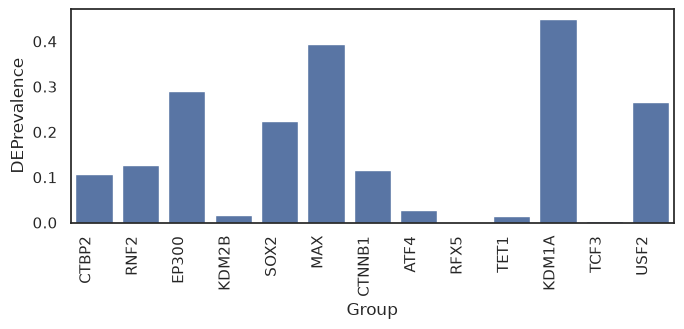

In [41]:
plt.figure(figsize=(7, 3))

sns.set(style='white')
# Base barplot
ax = sns.barplot(
    data=df1,
    x="Group",
    y="DEPrevalence"
)

plt.tight_layout()
plt.xticks(rotation=90, ha='right')
plt.savefig("perturb_kd_bar_deprevalence.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()